In [146]:
import os
import re
from datetime import datetime
import pandas as pd
import numpy as np
from plotnine import *
import baltic as bt
from geopy.distance import geodesic
import glob
import importlib

In [147]:
# This script provides code to analyze and plot the movement and direction of phylogenetic lineages
# First plots genetic change in latitude/longitude over each branch
# Then plots the trajectory of movement from node to tip three months later
# Input: MCC tree with host discrete traits and location continuous phylogeography

In [148]:
# TREEPATH = "./BEAST/continuous_phylogeography/results/2026-10-22_main-intro_equal-time-loc_ha_traits_mjr/main-intro_eq-time-loc_ha_traits_MCC.tree"
TREEPATH = "./BEAST/continuous_phylogeography/results/2026-10-22_main-intro_equal-time-loc_loc-host-shuff_ha_traits_mjr/main-intro_eq-time-loc_shuffle05_MCC.tree"
# TREEPATH = "./BEAST/continuous_phylogeography/results/2026-10-22_main-intro_equal-time-host-3000_ha_traits_mjr/main-intro_eq-time-host-3000_ha_traits_MCC.tree"
# TREEPATH = "./BEAST/continuous_phylogeography/results/2026-10-22_main-intro_equal-time-host-1000_ha_traits_mjr/main-intro_eq-time-host-1000_ha_traits_MCC.tree"
# TREEPATH = "./BEAST/continuous_phylogeography/results/2026-10-22_main-intro_prop-time-host_ha_traits_mjr/main-intro_prop-time-host_ha_traits_MCC.tree"
# TREEPATH = "./BEAST/continuous_phylogeography/results/2026-10-22_main-intro_prop-time-loc_ha_traits_mjr/main-intro_prop-time-loc_ha_traits_MCC.tree"
# TREEPATH = "./BEAST/continuous_phylogeography/results/2026-10-22_main-intro_liveharvest_ha_traits_mjr/main-intro_liveharvest_ha_traits_MCC.tree"

In [149]:
def load_tree(nexusPath):
    mytree = bt.loadNexus(nexusPath, tip_regex='\|([0-9]{4}\-[0-9]{2}\-[0-9]{2})', absoluteTime=True, verbose=False) # your tip regex might have to change or you could convert you tree into a newick by deleting everything before the tree string lol
    return(mytree)

In [150]:
# Load tree

tree = load_tree(TREEPATH)
print(tree.treeStats())


Tree height: 3.263636
Tree length: 411.124948
strictly bifurcating tree

Numbers of objects in tree: 8691 (4345 nodes and 4346 leaves)

None


In [151]:
def get_seasonyear(y):
    if y <= 2021.96986: # late autumn 2021
        return "autumn_2021"
    elif 2021.96986 < y <= 2022.21096: # winter 2021-22
        return "winter_2021/22"
    elif 2022.21096 < y <= 2022.46575: # spring 2022
        return "spring_2022"
    elif 2022.46575 < y <= 2022.72055: # summer 2022
        return "summer_2022"
    elif 2022.72055 < y <= 2022.96712: # autumn 2022
        return "autumn_2022"
    elif 2022.96712 < y <= 2023.21096: # winter 2022-23
        return "winter_2022/23"
    elif 2023.21096 < y <= 2023.46575: # spring 2023
        return "spring_2023"
    elif 2023.46575 < y <= 2023.72329: # summer 2023
        return "summer_2023"
    elif 2023.72329 < y <= 2023.96712: # autumn 2023
        return "autumn_2023"
    elif 2023.96712 < y <= 2024.21038: # winter 2023-24
        return "winter_2023/24"
    elif 2024.21038 < y <= 2024.46448: # spring 2024
        return "spring_2024"
    elif 2024.46448 < y <= 2024.72131: # summer 2024
        return "summer_2024"
    elif 2024.72131 < y <= 2024.96721: # autumn 2024
        return "autumn_2024"
    elif y > 2024.96721: # winter 2024
        return "winter_2024/25"
    else:
        return "unknown"

In [152]:
def get_monthyear(y):
    if 2021.665753 <= y < 2021.747945: 
        return "2021_september"
    elif 2021.747945 <= y < 2021.832877: 
        return "2021_october"
    elif 2021.832877 <= y < 2021.915068: 
        return "2021_november"
    elif 2021.915068 <= y < 2022.000000: 
        return "2021_december"
    elif 2022.000000 <= y < 2022.084932: 
        return "2022_january"
    elif 2022.084932 <= y < 2022.161644:
        return "2022_february"
    elif 2022.161644 <= y < 2022.246575:
        return "2022_march"
    elif 2022.246575 <= y < 2022.328767:
        return "2022_april"
    elif 2022.328767 <= y < 2022.413699:
        return "2022_may"
    elif 2022.413699 <= y < 2022.495890:
        return "2022_june"
    elif 2022.495890 <= y < 2022.580822:
        return "2022_july"
    elif 2022.580822 <= y < 2022.665753:
        return "2022_august"
    elif 2022.665753 <= y < 2022.747945:
        return "2022_september"
    elif 2022.747945 <= y < 2022.832877: 
        return "2022_october"
    elif 2022.832877 <= y < 2022.915068:
        return "2022_november"
    elif 2022.915068 <= y < 2023.000000:
        return "2022_december"
    elif 2023.000000 <= y < 2023.084932:
        return "2023_january"
    elif 2023.084932 <= y < 2023.161644:
        return "2023_february"
    elif 2023.161644 <= y < 2023.246575:
        return "2023_march"
    elif 2023.246575 <= y < 2023.328767:
        return "2023_2023_april"
    elif 2023.328767 <= y < 2023.413699:
        return "2023_may"
    elif 2023.413699 <= y < 2023.495890:
        return "2023_june"
    elif 2023.495890 <= y < 2023.580822:
        return "2023_july"
    elif 2023.580822 <= y < 2023.665753:
        return "2023_august"
    elif 2023.665753 <= y < 2023.747945:
        return "2023_september"
    elif 2023.747945 <= y < 2023.832877:
        return "2023_october"
    elif 2023.832877 <= y < 2023.915068:
        return "2023_november"
    elif 2023.915068 <= y < 2024.000000:
        return "2023_december"
    elif 2024.000000 <= y < 2024.084699:
        return "2024_january"
    elif 2024.084699 <= y < 2024.163934:
        return "2024_february"
    elif 2024.163934 <= y < 2024.248634:
        return "2024_march"
    elif 2024.248634 <= y < 2024.330601:
        return "2024_april"
    elif 2024.330601 <= y < 2024.415301:
        return "2024_may"
    elif 2024.415301 <= y < 2024.497268:
        return "2024_june"
    elif 2024.497268 <= y < 2024.581967:
        return "2024_july"
    elif 2024.581967 <= y < 2024.666667:
        return "2024_august"
    elif 2024.666667 <= y < 2024.748634:
        return "2024_september"
    elif 2024.748634 <= y < 2024.833333:
        return "2024_october"
    elif 2024.833333 <= y < 2024.915301:
        return "2024_november"
    elif y >= 2024.915301:
        return "2024_december"
    else:
        return "unknown"

In [153]:
def get_season(y):
    if y <= 2021.96986: # late autumn 2021
        return "autumn"
    elif 2021.96986 < y <= 2022.21096: # winter 2021-22
        return "winter"
    elif 2022.21096 < y <= 2022.46575: # spring 2022
        return "spring"
    elif 2022.46575 < y <= 2022.72055: # summer 2022
        return "summer"
    elif 2022.72055 < y <= 2022.96712: # autumn 2022
        return "autumn"
    elif 2022.96712 < y <= 2023.21096: # winter 2022-23
        return "winter"
    elif 2023.21096 < y <= 2023.46575: # spring 2023
        return "spring"
    elif 2023.46575 < y <= 2023.72329: # summer 2023
        return "summer"
    elif 2023.72329 < y <= 2023.96712: # autumn 2023
        return "autumn"
    elif 2023.96712 < y <= 2024.21038: # winter 2023-24
        return "winter"
    elif 2024.21038 < y <= 2024.46448: # spring 2024
        return "spring"
    elif 2024.46448 < y <= 2024.72131: # summer 2024
        return "summer"
    elif 2024.72131 < y <= 2024.96721: # autumn 2024
        return "autumn"
    elif y > 2024.96721: # winter 2024
        return "winter"
    else:
        return "unknown"

In [154]:
season_colors = {"winter":"#AA7722",
               "spring":"#5E9B82",
               "summer":"#C593D1",
               "autumn":"#2B57B3"
              }

season_labels = {"autumn_2021": "Autumn 2021", "winter_2021/22": "Winter 2021-22", "spring_2022": "Spring 2022", "summer_2022": "Summer 2022", 
                 "autumn_2022": "Autumn 2022","winter_2022/23": "Winter 2022-23", "spring_2023": "Spring 2023", "summer_2023": "Summer 2023", 
                 "autumn_2023": "Autumn 2023", "winter_2023/24": "Winter 2023-24", "spring_2024": "Spring 2024", "summer_2024": "Summer 2024", 
                 "autumn_2024": "Autumn 2024", "winter_2024/25": "Winter 2024-25"}

host_colors = {"bird-of-prey":"#C43110", # red-maroon
                     "duck":"#679C48", # green 
                     "goose-swan": "#DBB730", # yellow
                     "shorebird":"#68A0A6", # blue
                     "songbird-etc":"#D9A7B0", # pink
                     "ground-bird":"#E08907", # orange
                     "diving-bird":"#503A63", # deep purple
                     "other":"#A0A0A3" # grey
                    }

host_labels = {"bird-of-prey":"Birds of Prey", # red-maroon
                     "duck":"Ducks", # green 
                     "goose-swan": "Geese and Swans", # yellow
                     "shorebird":"Shorebirds and Seabirds", # blue
                     "songbird-etc":"Songbirds, Corvids, etc.", # pink
                     "ground-bird":"Ground Birds", # orange
                     "diving-bird":"Diving Birds", # deep purple
                     "other":"Other" # grey
                    }

In [155]:
# Function: calculates just the change in latitude and longitude for each branch 

def calculate_changeLatLong(t):
    
    change_distance = []
    
    for i in t.Objects:
        year = i.absoluteTime
        endLat = i.traits['location1']
        endLong = i.traits['location2']
        endHost = i.traits['host']
        if i.parent.traits == {}:
            # print("root")
            pass
        else:
            startLat = i.parent.traits['location1']
            startLong = i.parent.traits['location2']
            startHost = i.parent.traits["host"]
            changeLat = endLat - startLat
            changeLong = endLong - startLong
        
            change_distance.append({
                "date": year,
                "changeLat": changeLat,
                "changeLong":changeLong,
                "host":startHost
            })

    change_distance_df = pd.DataFrame(change_distance)

    return(change_distance_df)

In [156]:
# Calculate and plot the change in latitude and longitude for each branch so there is something to compare the trajectories plot to

changeLatLong = calculate_changeLatLong(tree)

changeLatLong["season"] = changeLatLong["date"].apply(get_seasonyear)
seasonyear_order = ["autumn_2021", "winter_2021/22", "spring_2022", "summer_2022", "autumn_2022", "winter_2022/23", "spring_2023", "summer_2023", "autumn_2023", "winter_2023/24", "spring_2024", "summer_2024", "autumn_2024", "winter_2024/25"]
changeLatLong["season"] = pd.Categorical(changeLatLong["season"], categories = seasonyear_order, ordered = True)

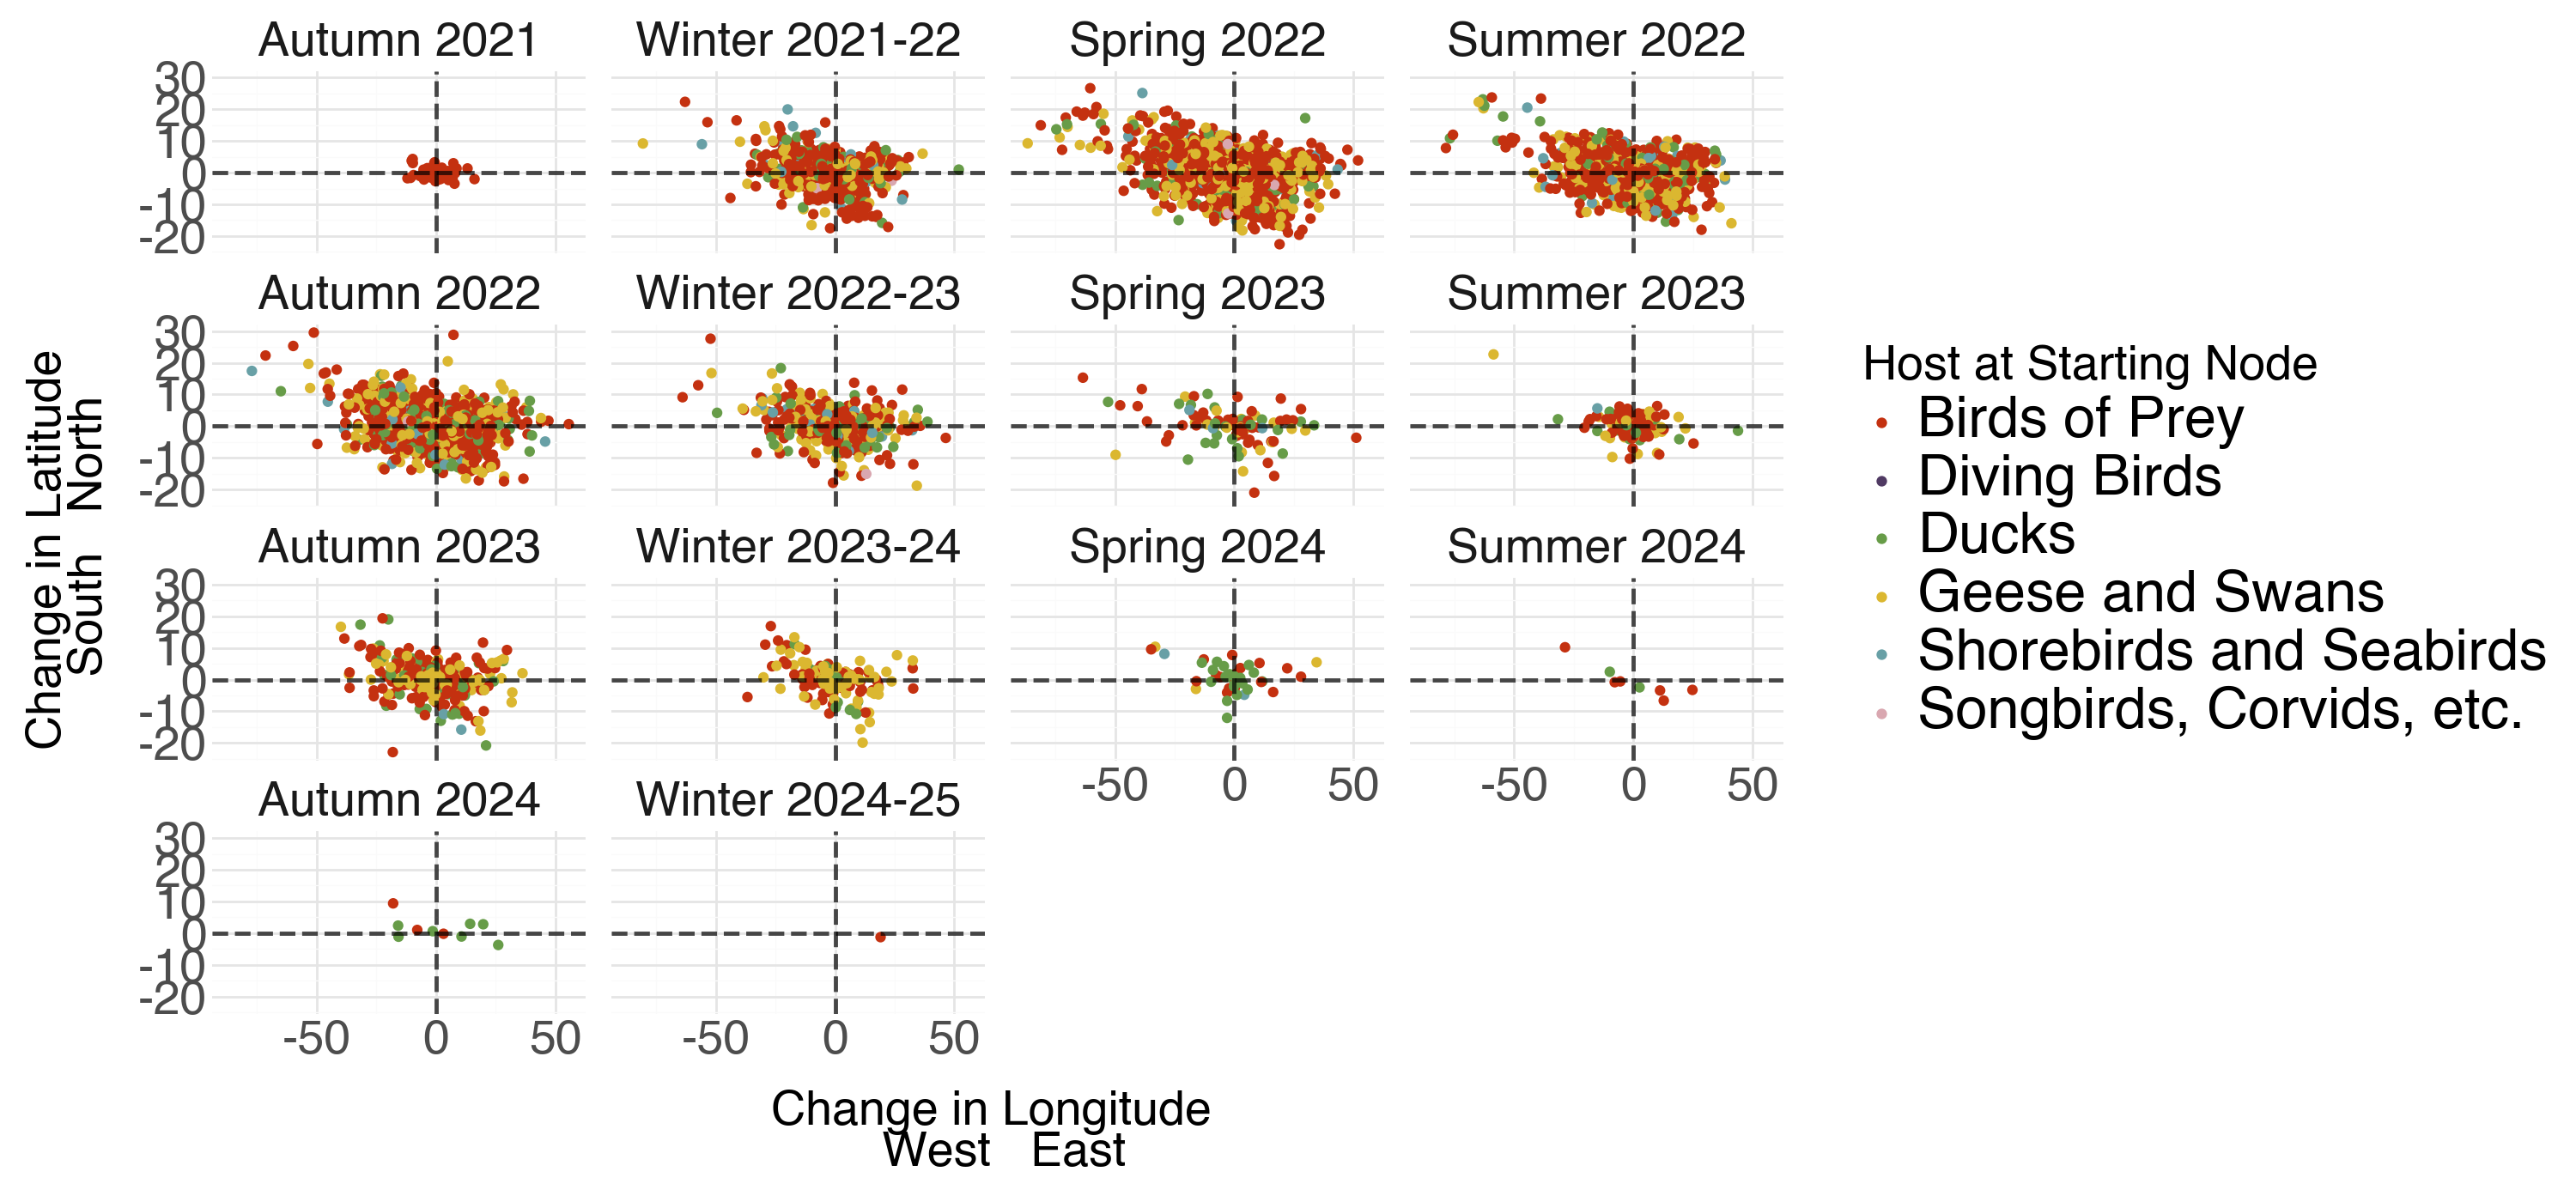

In [157]:
changeLatLong_plot = (
    ggplot(changeLatLong, aes(x = "changeLong", y = "changeLat", color = "host"))
    + geom_point()
    + facet_wrap("season", labeller = season_labels)
    + labs(x = "Change in Longitude \n West \t East", y = "Change in Latitude \n South \t North", color = "Host at Starting Node")
    + scale_color_manual(host_colors, labels = host_labels)
    + geom_hline(yintercept = 0, linetype = "dashed", size = 1, alpha = 0.7)
    + geom_vline(xintercept = 0, linetype = "dashed", size = 1, alpha = 0.7)
    + theme_minimal()
    + theme(figure_size = (15,7), legend_text=element_text(size=24), axis_title_x = element_text(size = 20), 
            axis_title_y = element_text(size = 20), text=element_text(size=20), axis_text_x = element_text(rotation = 0))
)

changeLatLong_plot.show()

In [158]:
# Now calculate the trajectories (a.k.a. the direction and distance of movement from a node to a tip, or along a lineage)

In [159]:
# Function: generate a list of nodes backwards in time from a leaf

def backwards(leaf, path_to_leaf, t, time):
    if time < t:
        path_to_leaf.append(leaf.parent)
        time += leaf.traits["length"]

        if leaf.parent.absoluteTime == None: # if parent is the root
            pass
        else:
            path_to_leaf = backwards(leaf.parent, path_to_leaf,t, time)
        
    return(path_to_leaf) # to add the latest node as a new "leaf", just print latest node and start afresh

In [160]:
# Make the parents dictionary, a dictionary with the path to a node 3 months back in time for each leaf

count = 0
parents = {}

for k in tree.Objects:
    t = 0.25 # 0.25 years is about 3 months
    # t = 0.0833 # 0.0833 years is about 1 month
    # if count < 30:
    if k.is_node():
        pass
    else:
        path_to_leaf = []
        time = 0
        path_to_leaf = backwards(k, path_to_leaf, t, time)
        # parents = defaultdict(path_to_leaf)
        # parents[k.name] = path_to_leaf
        parents.update({k:{"path":path_to_leaf}})
        # count += 1

In [161]:
# Pick just the node furthest back in time

for key in parents:
    
    parents[key]["earliest_node"] = []

    list_of_nodes = parents[key]["path"]

    node_times_dict = {}
    for node in list_of_nodes:
        if node.absoluteTime == None: # Just in case the root is the node 3 months away from a tip
            pass
        else:
            node_times_dict.update({node:node.absoluteTime}) 

    min_key = min(node_times_dict, key=lambda k: node_times_dict[k]) # takes the minimum value in the dictionary, sets a function using lambda to return the key of that minimum
    # print("Key with minimum value:", min_key)

    parents[key]["earliest_node"] = min_key

In [162]:
# Function: calculate distance between leaf and each node

def calc_dist(node, leaf_lat, leaf_long):
    # For each node, pull the lat/long
    node_lat = node.traits["location1"]
    node_long = node.traits["location2"]

    # Establish coordinates
    start = (node_lat, node_long)
    end = (leaf_lat, leaf_long)

    # Calculate distance
    dist = geodesic(start, end, ellipsoid='GRS-80').kilometers

    return(dist)

In [163]:
# Function: calculate direction of movement

def calc_direction(node, leaf_lat, leaf_long):
    # For each node, pull the lat/long
    node_lat = node.traits["location1"]
    node_long = node.traits["location2"]

    # Calculate change in latitude (and set to direction)
    changeLat = float(leaf_lat - node_lat)
    # print(changeLat)
    if changeLat < 0:
        directLat = "south"
    elif changeLat > 0:
        directLat = "north"
    else:
        directLat = "none"

    # Calculate change in longitude (and set to direction)
    changeLong = float(leaf_long - node_long)
    # print(changeLong)
    if changeLong < 0:
        directLong = "west"
    elif changeLong > 0:
        directLong = "east"
    else:
        directLong = "none"

    # Combine
    return(changeLat, changeLong, directLat, directLong)
    # return(directLat_directLong)

In [164]:
# Function: determine the season of the starting node

def calc_nodeseason(node):
    
    node_time = node.absoluteTime

    # Assign season to leaf and node
    season = get_season(node_time)
    
    return(season)

In [165]:
# Function: determine the "timing" of the starting node
# In this case, timing the start node by the season and year it occurs in

def calc_timing(node):

    node_time = node.absoluteTime

    # node_year = node_time.as_type(str).str.split(".", expand = True)[0]

    node_timing = get_seasonyear(node_time)
    # node_timing = get_monthyear(node_time)

    return(node_timing)

In [166]:
# Function: This loop calculates year, change in season, distance, change in Latitude, and change in Longitude between a leaf and a node three months back in the lineage

def make_metadata(dictionary):
    for key in dictionary:
        
        # Set leaf (ending) latitude and longitude
        leaf_lat = key.traits["location1"]
        leaf_long = key.traits["location2"]
    
        # Use the following if you want to calculate distance, change in Latitude, and change in Longitude for each node in the path backwards
        
        # # Update the parents dictionary
        # dictionary[key]["distance"] = []
        # dictionary[key]["changeLatitude"] = []
        # dictionary[key]["changeLongitude"] = []
        # dictionary[key]["node_season"] = []
        # dictionary[key]["node_timing"] = []
    
        # # Initialize the lists 
        # distance = []
        # changeLat = []
        # changeLong = []
        # season = []
        # timing = []
    
        # nodes_backward = dictionary[key]["path"] 
        # # print(nodes_backward)
    
        # for node in nodes_backward:
        #     node_dist = calc_dist(node, leaf_lat, leaf_long)
        #     distance.append(node_dist)
        #     node_changeLat, node_changeLong = calc_direction(node, leaf_lat, leaf_long)
        #     changeLat.append(node_changeLat)
        #     changeLong.append(node_changeLong)
        #     node_season = calc_nodeseason(node)
        #     node_timing = calc_timing(node)
        #     season.append(node_season)
        #     timing.append(node_timing)
        
    
        # # print(distance)
    
        # dictionary[key]["distance"] = distance
        # dictionary[key]["changeLatitude"] = changeLat
        # dictionary[key]["changeLongitude"] = changeLong
        # dictionary[key]["node_season"] = season
        # dictionary[key]["node_timing"] = timing
    
    
        # Use this code if you want to calculate distance, change in Latitude, and change in Longitude for just the earliest node (most backwards)
        node = dictionary[key]["earliest_node"] 
        
        node_dist = calc_dist(node, leaf_lat, leaf_long)
        node_changeLat, node_changeLong, node_directLat, node_directLong = calc_direction(node, leaf_lat, leaf_long)
        node_season = calc_nodeseason(node)
        node_timing = calc_timing(node)
        node_year = str(node.absoluteTime).split(".")[0]
        node_host = node.traits["host"]
        leaf_host = key.traits["host"]
    
        dictionary[key]["distance"] = node_dist
        dictionary[key]["changeLatitude"] = node_changeLat
        dictionary[key]["changeLongitude"] = node_changeLong
        dictionary[key]["node_season"] = node_season
        dictionary[key]["node_timing"] = node_timing
        dictionary[key]["directionLatitude"] = node_directLat
        dictionary[key]["directionLongitude"] = node_directLong
        dictionary[key]["node_year"] = node_year
        dictionary[key]["node_host"] = node_host
        dictionary[key]["leaf_host"] = leaf_host

    return(dictionary)

In [167]:
# Make metadata for each tip and its corresponding node three months back

parents = make_metadata(parents)
parents_df = pd.DataFrame.from_dict(parents, orient = "index")
parents_df["node_timing"] = pd.Categorical(parents_df["node_timing"], categories=seasonyear_order, ordered=True)

In [168]:
print(len(parents_df))

4346


In [169]:
# Want to just plot the node-to-tip trajectory where host is consistent
# This is because the trajectory of branches where the host group changes is some combo of the trajectory of each host, which is hard to understand/explain

parents_df_nontrans = parents_df.loc[parents_df["node_host"] == parents_df["leaf_host"]]

# If want to include branches where host group changes
# Then make it a separate color

parents_df_colortrans = parents_df.copy()
parents_df_colortrans["node_host_w-color-trans"] = parents_df_colortrans["node_host"]
parents_df_colortrans.loc[(parents_df["node_host"] != parents_df["leaf_host"]), "node_host_w-color-trans"] = "transition"

In [170]:
# Function: calculate the proportion trajectories moving in each direction for each season (to add as text to the figures)

def calc_proportions(df, group):

    grouped = df.groupby(group) # group by season_year or season or month

    prop_dict = {}

    for group in grouped: 
        prop_dict[group[0]] = {}
        total = len(group[1]) # total number of nodes that start in that month
        if total != 0:
            nw = len(group[1].loc[(group[1]["directionLatitude"] == "north") & (group[1]["directionLongitude"] == "west")])
            ne = len(group[1].loc[(group[1]["directionLatitude"] == "north") & (group[1]["directionLongitude"] == "east")])
            sw = len(group[1].loc[(group[1]["directionLatitude"] == "south") & (group[1]["directionLongitude"] == "west")])
            se = len(group[1].loc[(group[1]["directionLatitude"] == "south") & (group[1]["directionLongitude"] == "east")])

            prop_nw = round(((nw/total) * 100), 2)
            prop_ne = round(((ne/total) * 100), 2)
            prop_sw = round(((sw/total) * 100), 2)
            prop_se = round(((se/total) * 100), 2)

            # n = len(group[1].loc[group[1]["directionLatitude"] == "north"])
            # s = len(group[1].loc[group[1]["directionLatitude"] == "south"])
            
            # prop_n = round(((n/total) * 100), 2)
            # prop_s = round(((s/total) * 100), 2)
        else: 
            pass
        
        prop_dict[group[0]] = {"percent-NW": prop_nw, "percent-NE": prop_ne, "percent-SW": prop_sw, "percent-SE": prop_se}
        # prop_dict[group[0]] = {"percent-N": prop_n, "percent-S": prop_s}

    text_df = pd.DataFrame(prop_dict).T

    return(text_df)

In [171]:
# text = calc_proportions(parents_df_nontrans, "node_timing")
text = calc_proportions(parents_df_colortrans, "node_timing")
new_text = text.reset_index().rename({"index":"node_timing"}, axis = 1)
new_text["node_timing"] = pd.Categorical(new_text["node_timing"], categories=seasonyear_order, ordered=True)

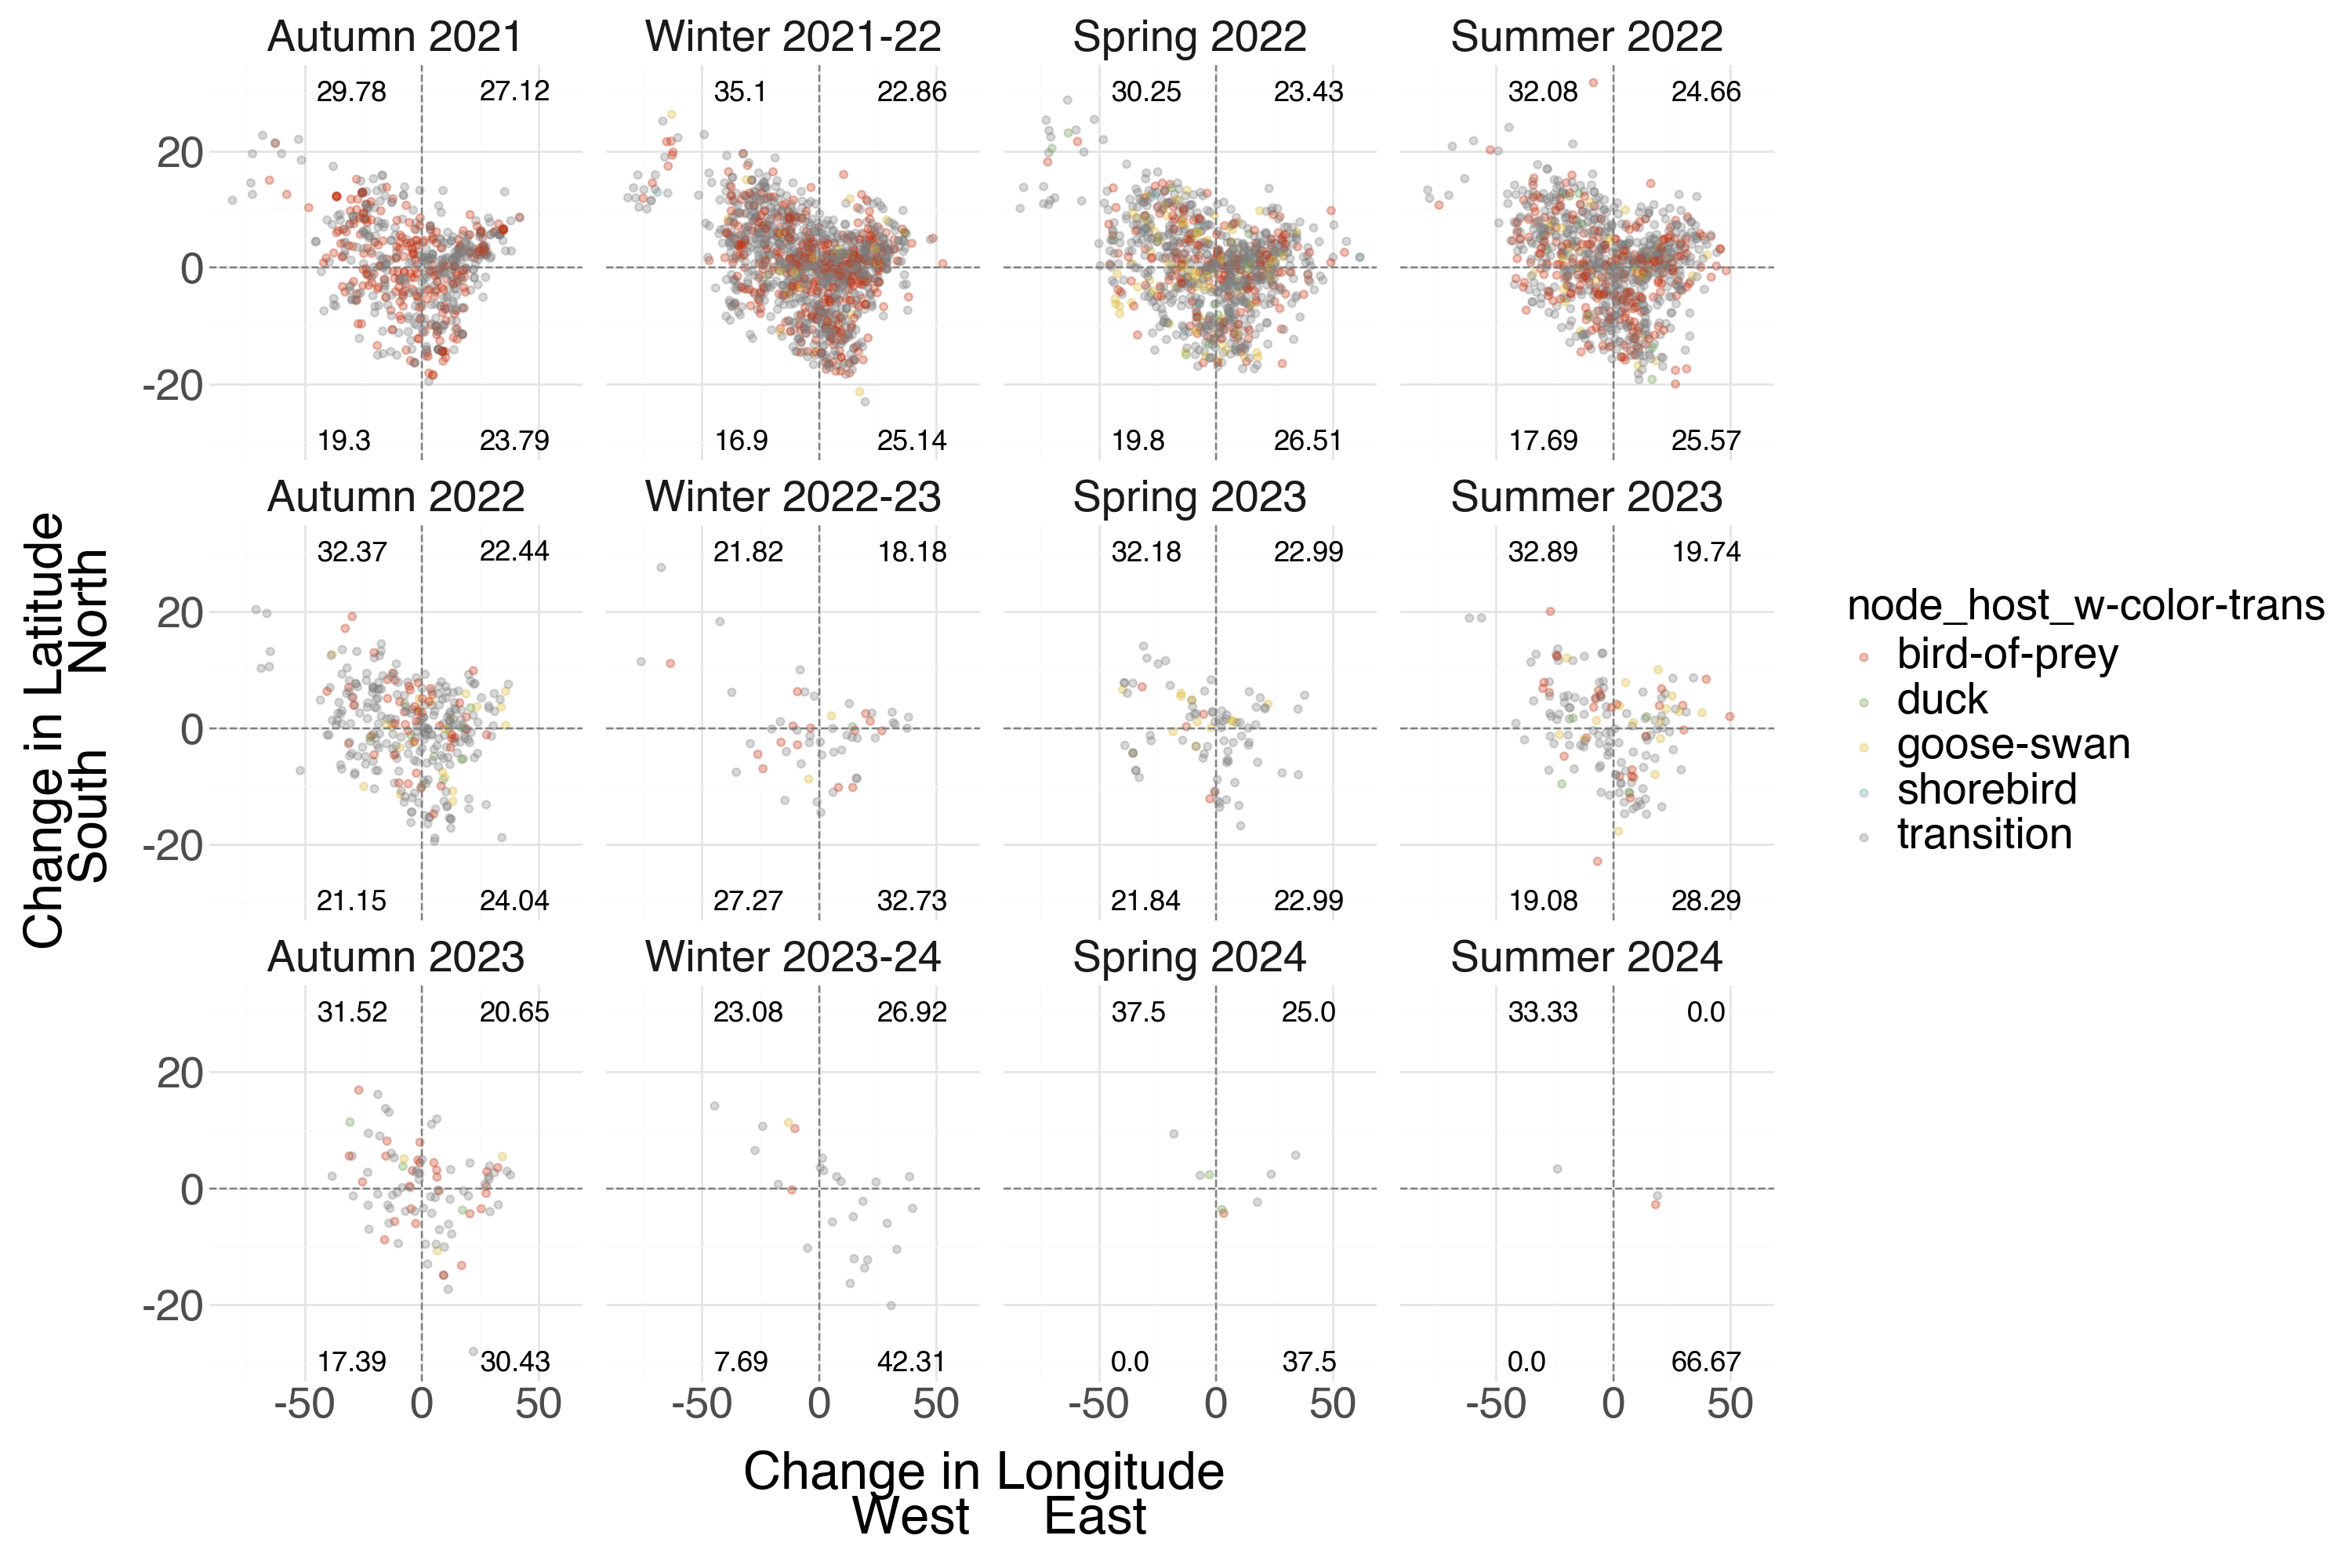

In [172]:
# Plot the trajectory of lineages from node to tip three months later

trajectory_plot = (
    # ggplot(parents_df_nontrans, aes(x = "changeLongitude", y = "changeLatitude", color = "node_host"))
    ggplot(parents_df_colortrans, aes(x = "changeLongitude", y = "changeLatitude", color = "node_host_w-color-trans"))
    + geom_point(alpha = 0.3)
    + facet_wrap("node_timing", labeller = season_labels)
    # + xlim(-15, 15)
    # + ylim(-15, 15)
    + scale_color_manual(host_colors)
    + geom_vline(xintercept = 0, linetype = "dashed", color = "grey")
    + geom_hline(yintercept = 0, linetype = "dashed", color = "grey")
    + geom_text(new_text, aes(x=-45, y=30, label="percent-NW"), color="black",size=13, ha='left')
    + geom_text(new_text, aes(x=-45, y=-30, label="percent-SW"), color="black",size=13, ha='left')
    + geom_text(new_text, aes(x=40, y=30, label="percent-NE"), color="black",size=13, ha='center')
    + geom_text(new_text, aes(x=40, y=-30, label="percent-SE"), color="black",size=13, ha='center')
    + labs(x = "Change in Longitude \n West \t\t\t East", y = "Change in Latitude \n South \t\t\t North") #, title = "If a node occurs in a certain season, in which direction will it's tip have moved after three months?")
    + theme_minimal()
    + theme(figure_size = (15, 10), legend_text=element_text(size=20), axis_title_x = element_text(size = 24), 
            axis_title_y = element_text(size = 24), text=element_text(size=20))
)

trajectory_plot.show()

In [173]:
# DIRECTORY = "equal-time-location"
DIRECTORY = "equal-time-location_shuffled"
# DIRECTORY = "equal-time-host-3000"
# DIRECTORY = "equal-time-host-1000"
# DIRECTORY = "proportional-time-host"
# DIRECTORY = "proportional-time-location"
# DIRECTORY = "live-harvest"

In [174]:
# Print dataframe for later comparison (if necessary)

parents_df.to_csv(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/trajectories_dataframe.tsv", sep = "\t")

In [116]:
changeLatLong_plot.save(filename = f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/latlong-change_hostcolor.pdf", height=10, width=15, units = 'in', dpi=750)
trajectory_plot.save(filename = f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/trajectories_3mo_hostcolor.pdf", height=10, width=15, units = 'in', dpi=750)

changeLatLong_plot.save(filename = f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/latlong-change_hostcolor.png", height=10, width=15, units = 'in', dpi=750)
trajectory_plot.save(filename = f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/trajectories_3mo_hostcolor.png", height=10, width=15, units = 'in', dpi=750)

/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 15 x 10 in image.
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ./analyses/main-intro_six-datasets_mjr/equal-time-location_shuffled/latlong-change_hostcolor.pdf
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 15 x 10 in image.
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ./analyses/main-intro_six-datasets_mjr/equal-time-location_shuffled/trajectories_3mo_hostcolor.pdf
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 15 x 10 in image.
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ./analyse

In [145]:
# Below, I compare two trajectories to see if they differ

In [182]:
# Read in the two dataframes to compare

ONE = "./analyses/main-intro_six-datasets_mjr/equal-time-location/trajectories_dataframe.tsv"
TWO = "./analyses/main-intro_six-datasets_mjr/equal-time-location_shuffled/trajectories_dataframe_shuffle05.tsv"

dataset1 = pd.read_csv(ONE, sep = "\t")
dataset2 = pd.read_csv(TWO, sep = "\t")

dataset1["node_timing"] = pd.Categorical(dataset1["node_timing"], categories=seasonyear_order, ordered=True)
dataset2["node_timing"] = pd.Categorical(dataset2["node_timing"], categories=seasonyear_order, ordered=True)

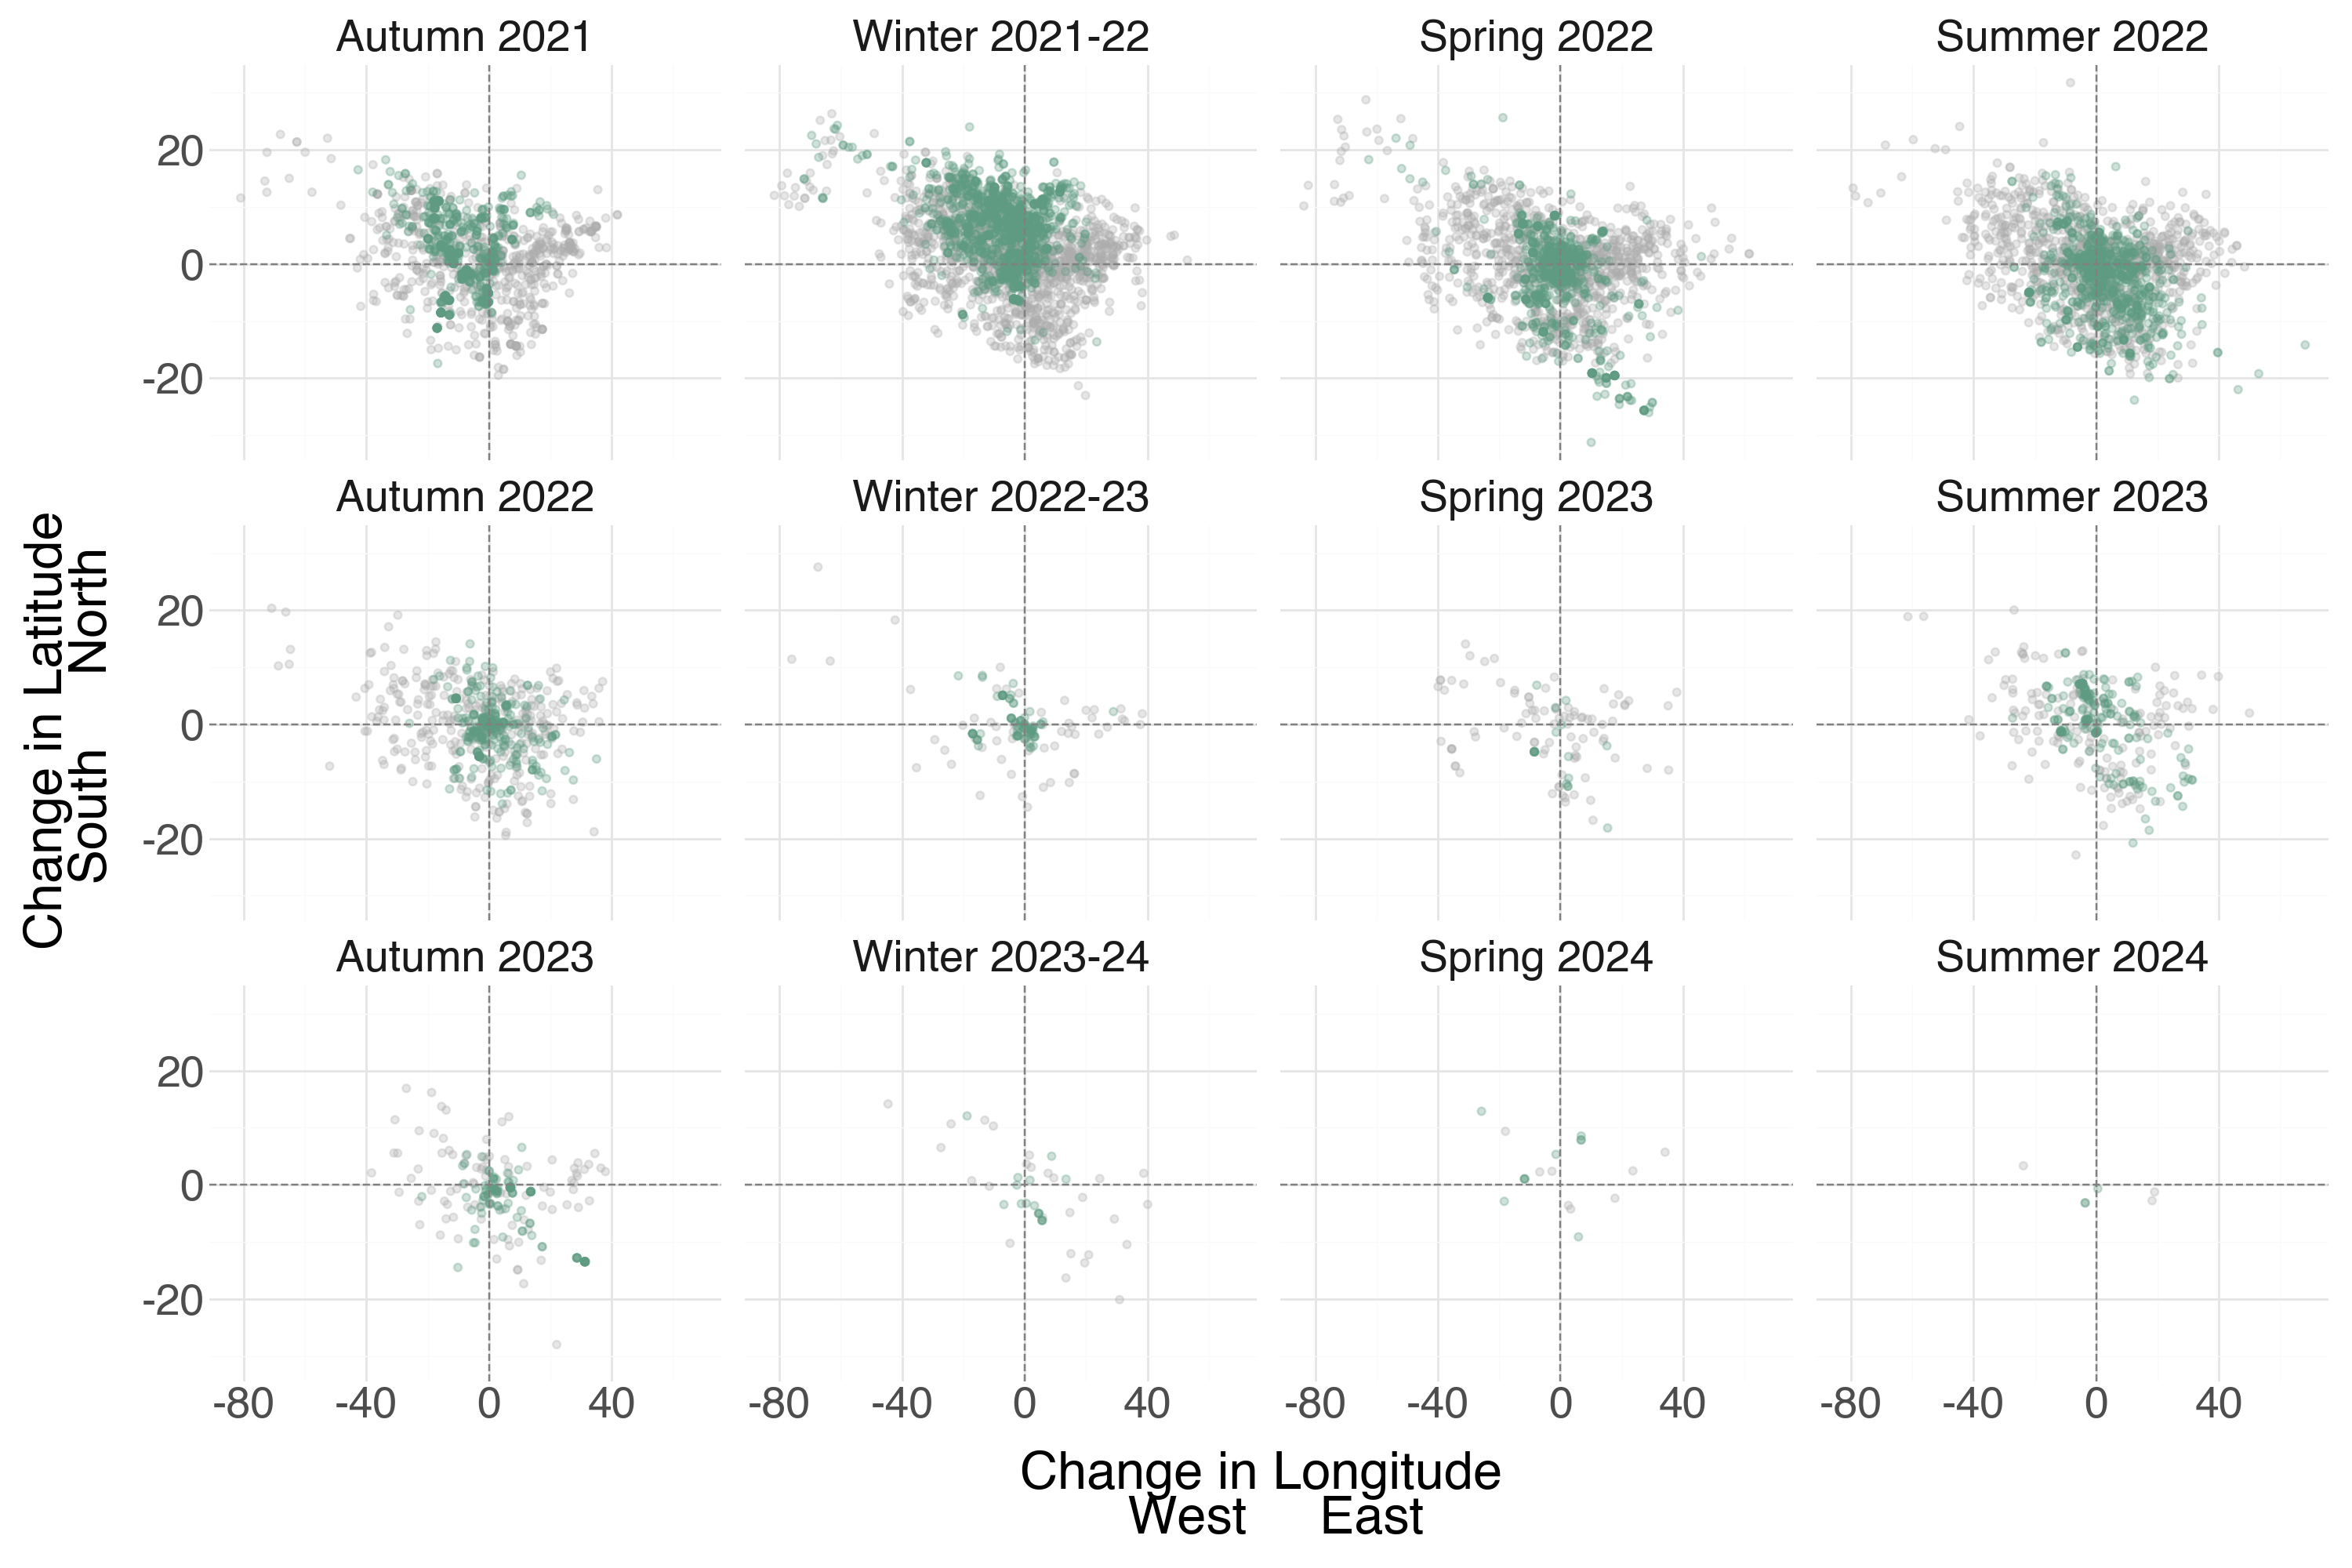

In [184]:
compare_trajectories_plot_1 = (
    ggplot() 
    + geom_point(dataset2, aes(x = "changeLongitude", y = "changeLatitude"), color = "#ADADAD", alpha = 0.3) # shuffled
    + geom_point(dataset1, aes(x = "changeLongitude", y = "changeLatitude"), color = "#5E9B82", alpha = 0.3) # original
    + facet_wrap("node_timing", labeller = season_labels)
    # + xlim(-15, 15)
    # + ylim(-15, 15)
    + geom_vline(xintercept = 0, linetype = "dashed", color = "grey")
    + geom_hline(yintercept = 0, linetype = "dashed", color = "grey")
    + labs(x = "Change in Longitude \n West \t\t\t East", y = "Change in Latitude \n South \t\t\t North") #, title = "If a node occurs in a certain season, in which direction will it's tip have moved after three months?")
    + theme_minimal()
    + theme(figure_size = (15, 10), legend_text=element_text(size=20), axis_title_x = element_text(size = 24), 
            axis_title_y = element_text(size = 24), text=element_text(size=20))
)

compare_trajectories_plot_1.show()

In [201]:
dataset1["dataset"] = "original"
dataset2["dataset"] = "shuffled"

combined_datasets = pd.concat([dataset1, dataset2])

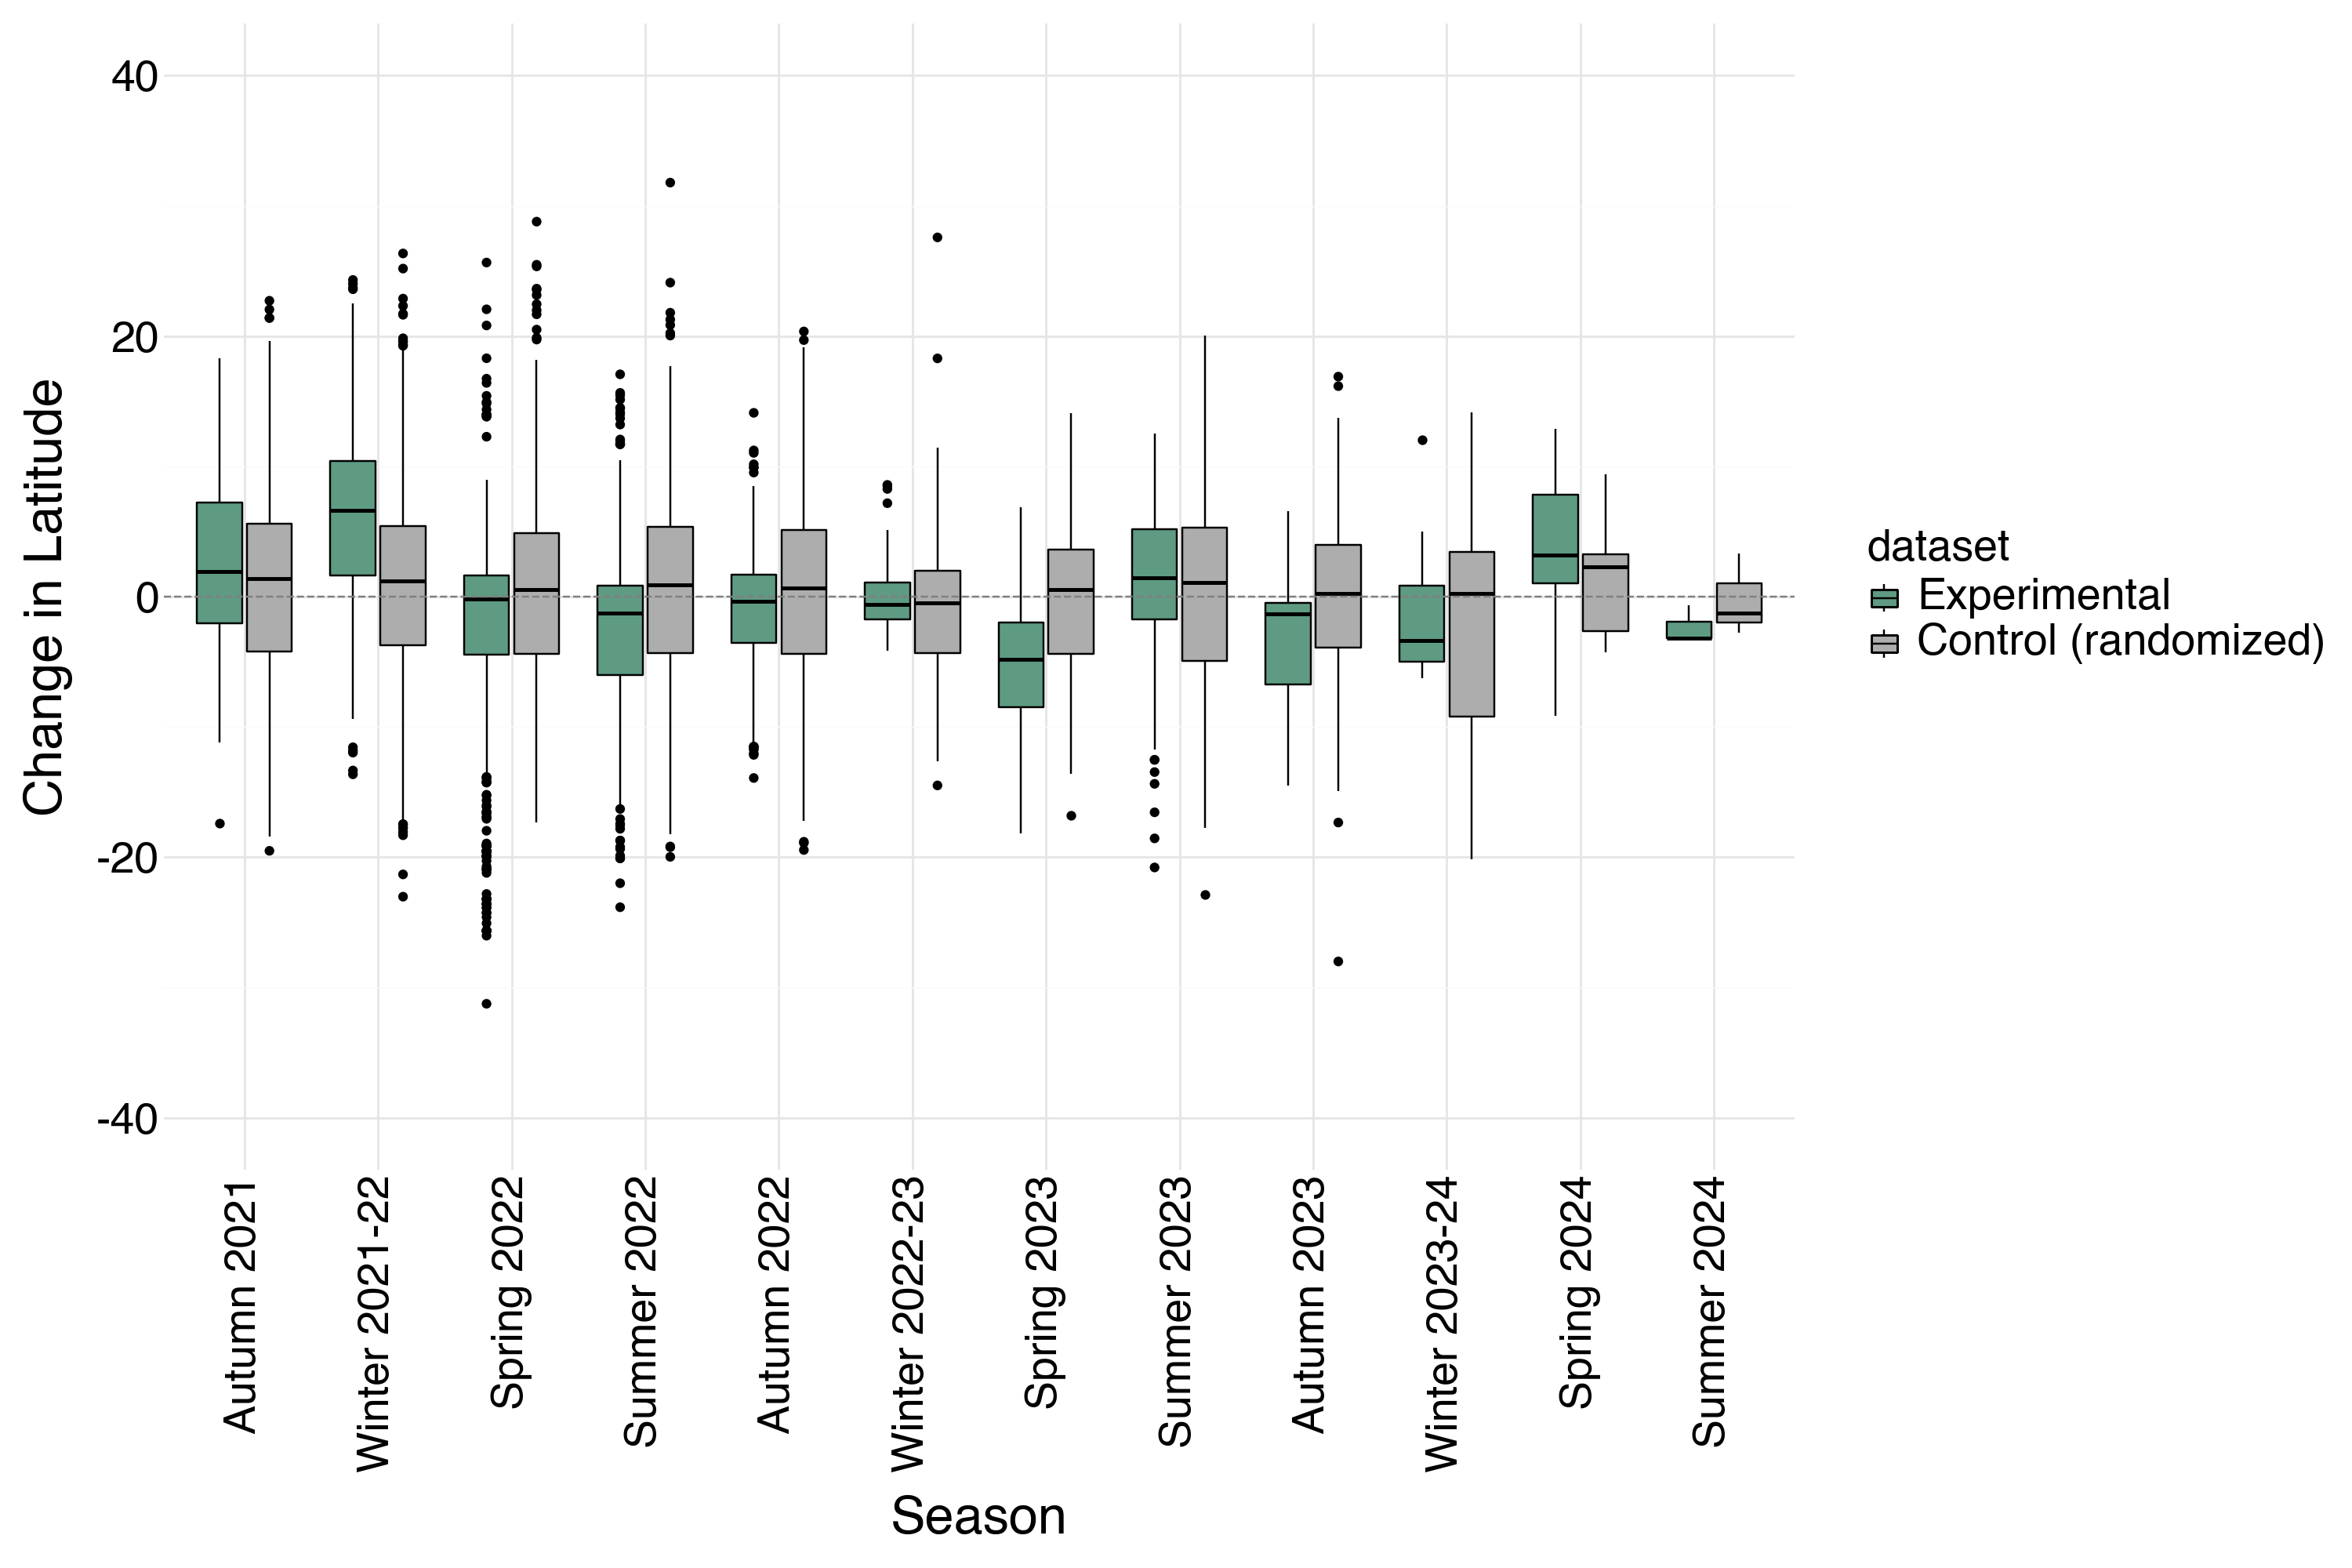

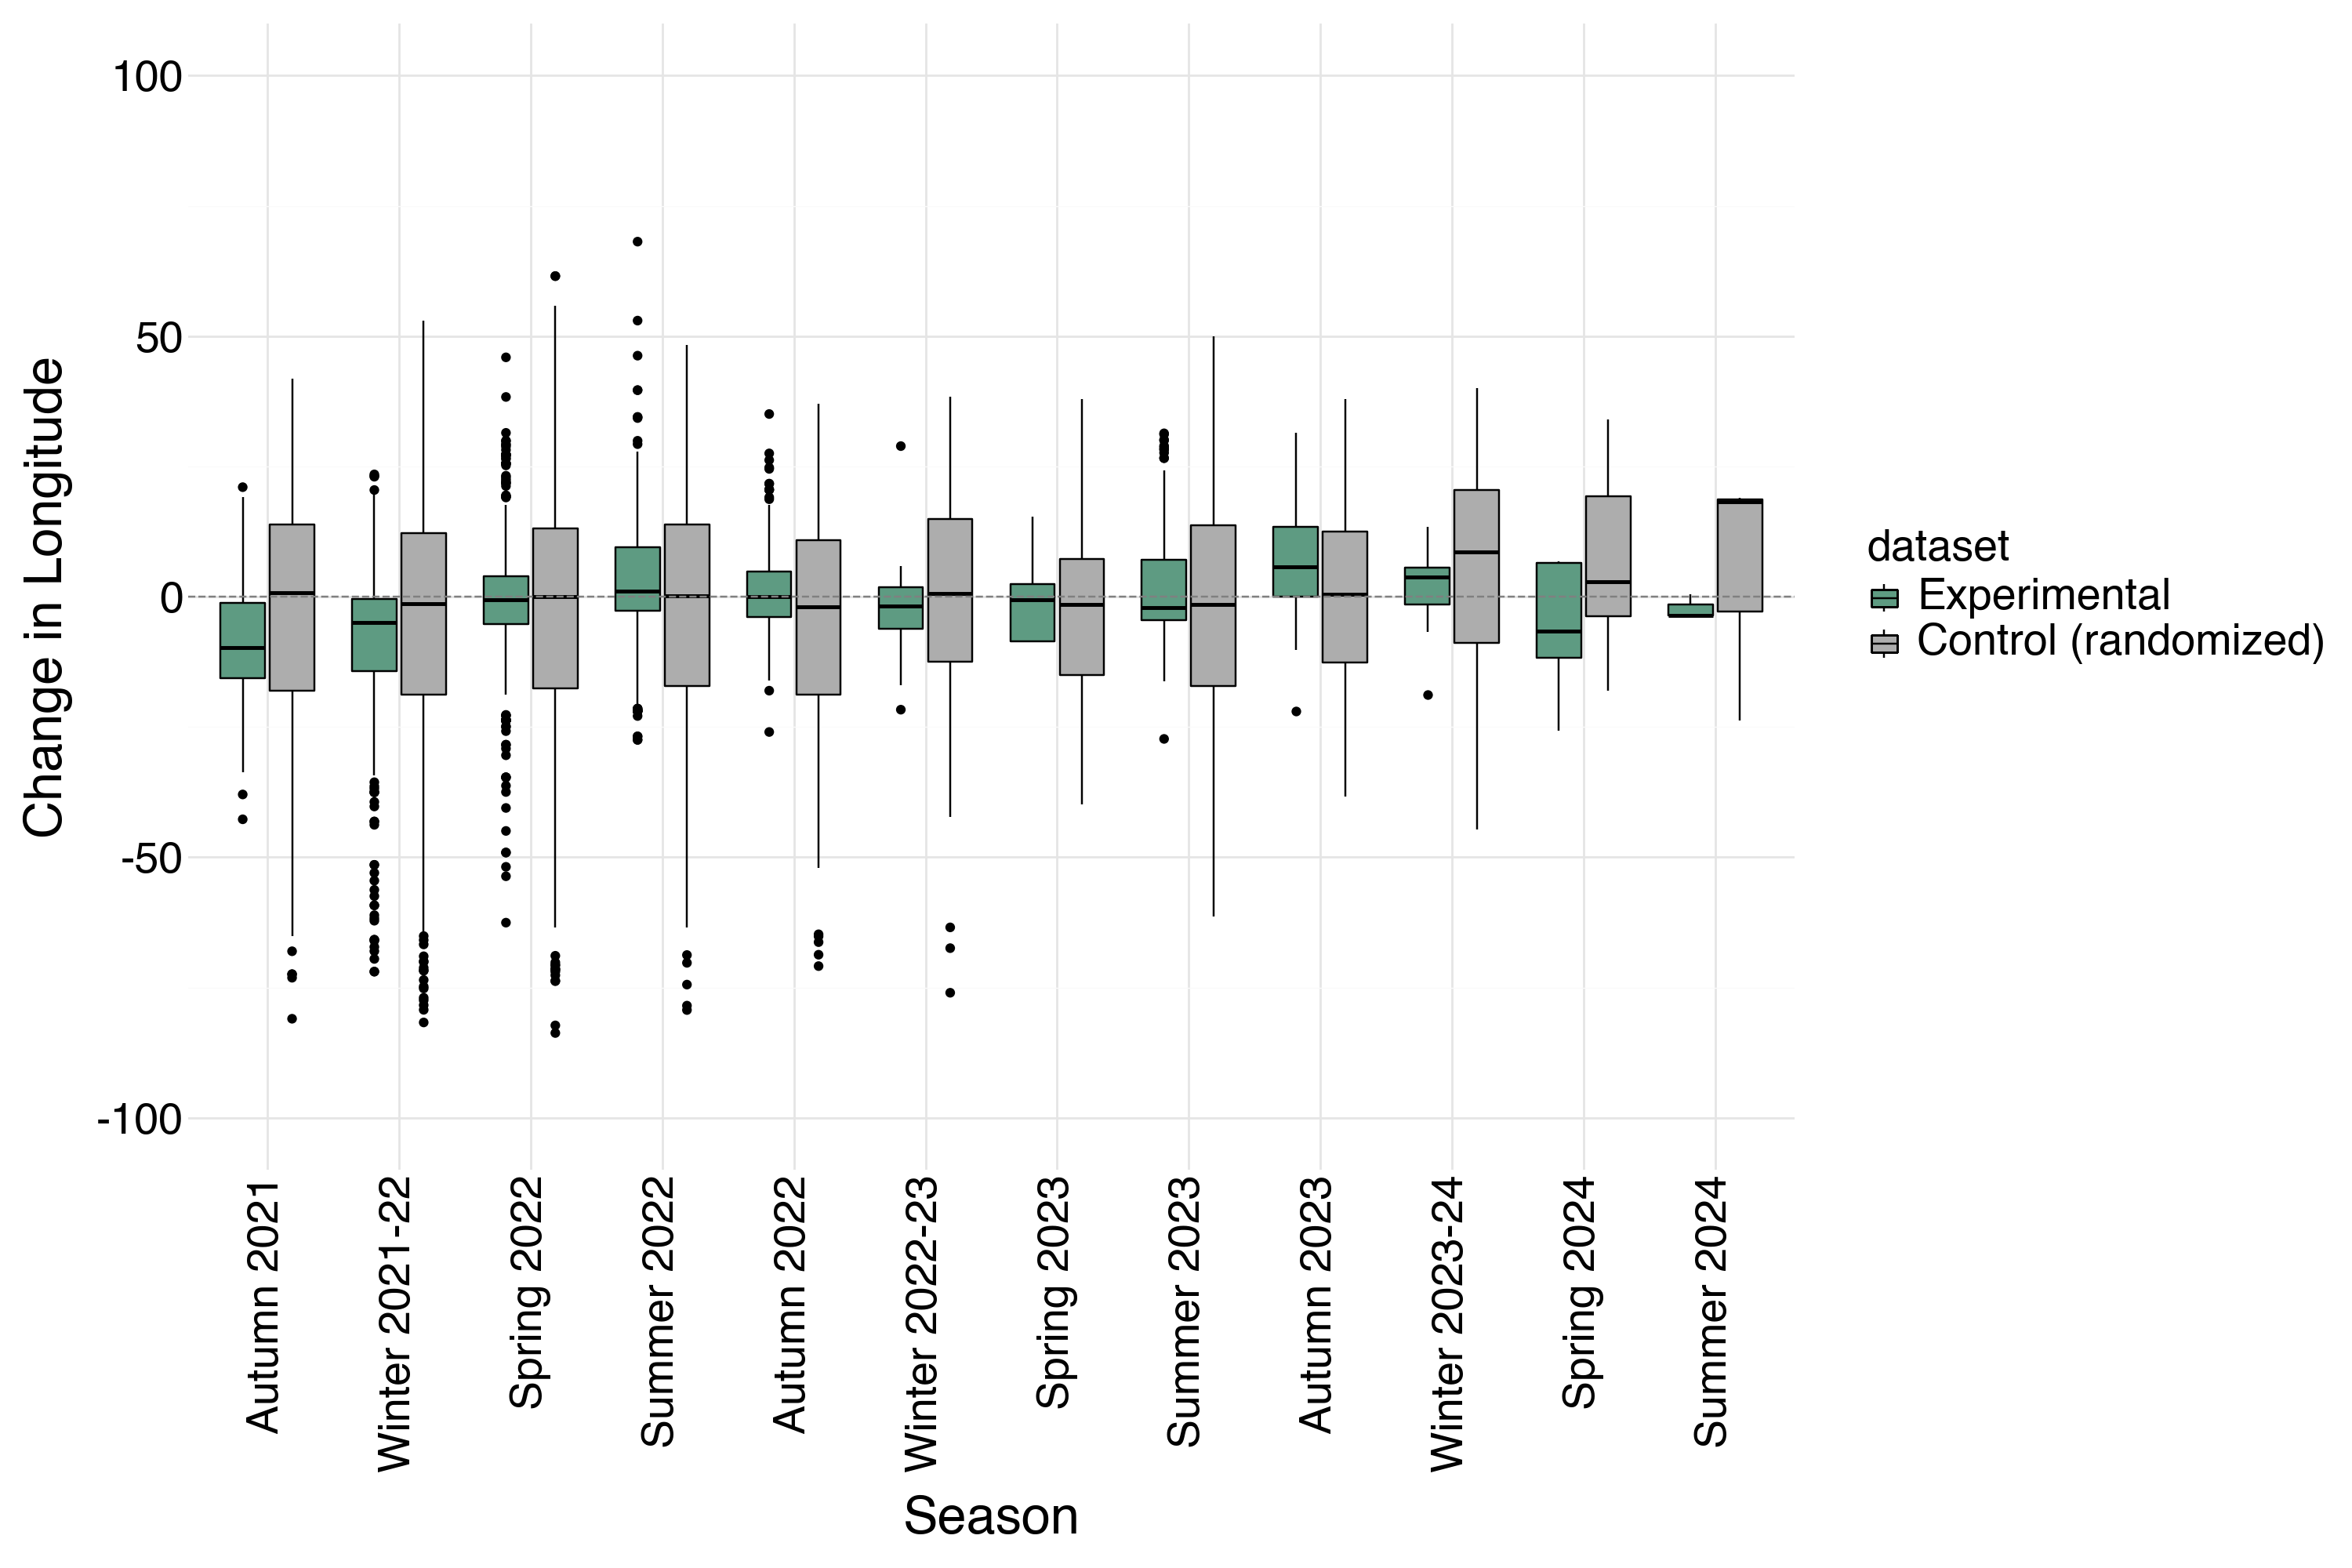

In [207]:
compare_trajectories_plot_2A = (
    ggplot() 
    + geom_boxplot(combined_datasets, aes(x = "node_timing", y = "changeLatitude", fill = "dataset"), color = "black")
    + scale_x_discrete(labels = season_labels)
    + scale_fill_manual(values = {"original":"#5E9B82", "shuffled":"#ADADAD"}, labels = {"original":"Experimental", "shuffled":"Control (randomized)"})
    + geom_hline(yintercept = 0, linetype = "dashed", color = "grey")
    + labs(x = "Season", y = "Change in Latitude")
    + ylim(-40, 40)
    + theme_minimal()
    + theme(figure_size = (15, 10), 
            legend_text=element_text(size=20), text=element_text(size=20),
            axis_title_x = element_text(size = 24), axis_text_x = element_text(size = 20, color = "black", rotation = 90),
            axis_title_y = element_text(size = 24), axis_text_y = element_text(size = 20, color = "black"))
)

compare_trajectories_plot_2B = (
    ggplot() 
    + geom_boxplot(combined_datasets, aes(x = "node_timing", y = "changeLongitude", fill = "dataset"), color = "black")
    + scale_x_discrete(labels = season_labels)
    + scale_fill_manual(values = {"original":"#5E9B82", "shuffled":"#ADADAD"}, labels = {"original":"Experimental", "shuffled":"Control (randomized)"})
    + geom_hline(yintercept = 0, linetype = "dashed", color = "grey")
    + labs(x = "Season", y = "Change in Longitude")
    + ylim(-100, 100)
    + theme_minimal()
    + theme(figure_size = (15, 10), 
            legend_text=element_text(size=20), text=element_text(size=20),
            axis_title_x = element_text(size = 24), axis_text_x = element_text(size = 20, color = "black", rotation = 90),
            axis_title_y = element_text(size = 24), axis_text_y = element_text(size = 20, color = "black"))
)

compare_trajectories_plot_2A.show()
compare_trajectories_plot_2B.show()